Import Required Libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import zipfile

from google.colab import files
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)
from IPython.display import display

load the images

In [2]:
import os

print("Files in /content:")
print(os.listdir("/content"))

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

image_files = sorted([
    f for f in os.listdir("/content")
    if f.lower().endswith(image_extensions)
    and os.path.isfile(os.path.join("/content", f))
])

print("\nImages Found:")
print(image_files)
print("Total Images:", len(image_files))

Files in /content:
['.config', 'image-1.png', 'image-3.png', 'image-2.png', 'sample_data']

Images Found:
['image-1.png', 'image-2.png', 'image-3.png']
Total Images: 3


Read and Display Images

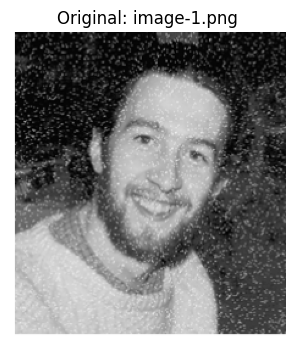

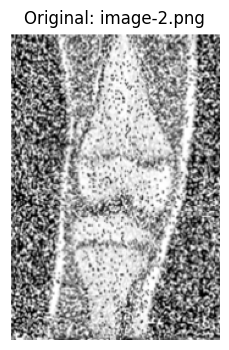

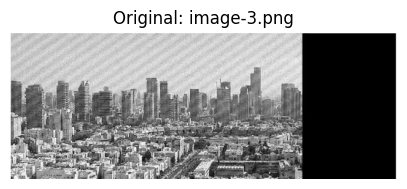

Total Images Loaded: 3


In [3]:
images = {}

for name in image_files:

    path = os.path.join("/content", name)

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is not None:
        images[name] = img

        plt.figure(figsize=(5, 4))
        plt.imshow(img, cmap="gray")
        plt.title("Original: " + name)
        plt.axis("off")
        plt.show()

print("Total Images Loaded:", len(images))

Define Frequency-Domain Filters

In [4]:
def frequency_filters(img, cutoff=30, order=2):

    rows, cols = img.shape

    F = np.fft.fft2(img)
    F_shift = np.fft.fftshift(F)

    u = np.arange(rows) - rows // 2
    v = np.arange(cols) - cols // 2

    V, U = np.meshgrid(v, u)

    D = np.sqrt(U**2 + V**2)

    # Ideal Low-Pass Filter
    ideal = (D <= cutoff).astype(float)

    # Butterworth Low-Pass Filter
    butterworth = 1 / (
        1 + (D / cutoff)**(2 * order)
    )

    # Gaussian Low-Pass Filter
    gaussian = np.exp(
        -(D**2) / (2 * cutoff**2)
    )

    return F_shift, ideal, butterworth, gaussian

Apply Frequency-Domain Smoothing

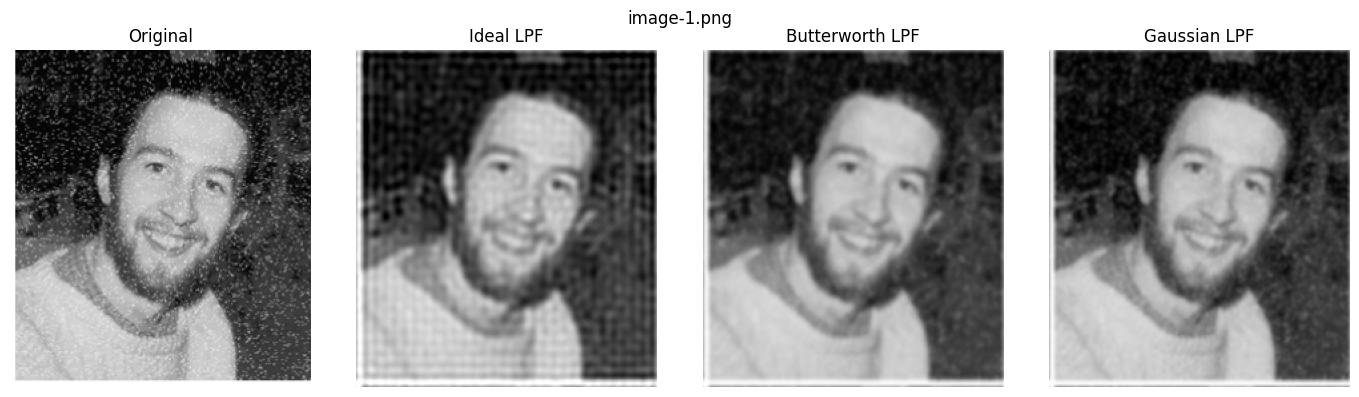

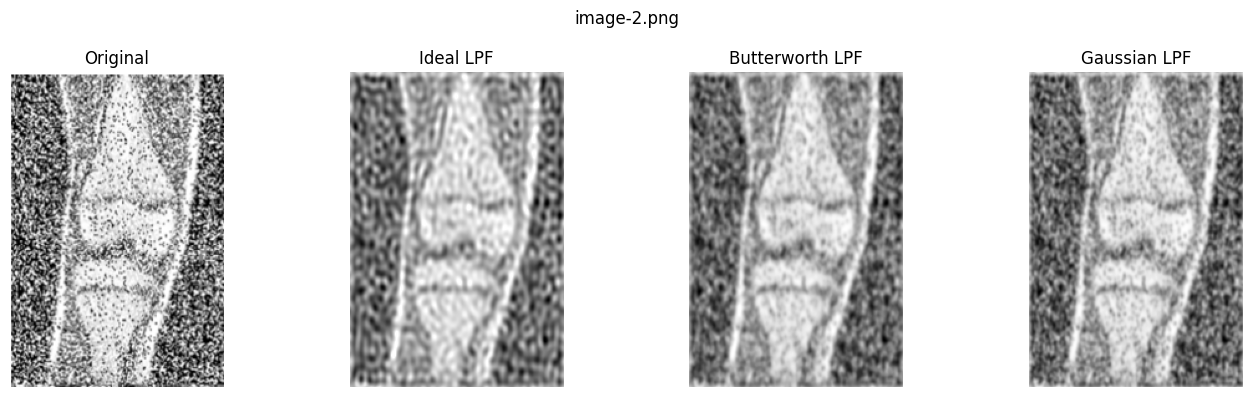

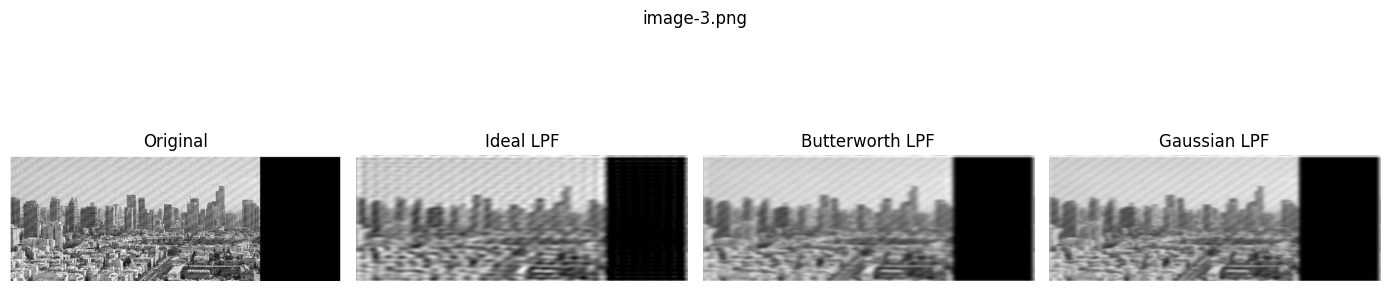

In [5]:
def apply_filter(F_shift, filter_mask):

    filtered = F_shift * filter_mask

    img_back = np.fft.ifft2(
        np.fft.ifftshift(filtered)
    )

    img_back = np.real(img_back)

    return np.clip(img_back, 0, 255).astype(np.uint8)


smoothed_images = {}

for name, img in images.items():

    F, ideal, butter, gaussian = frequency_filters(
        img, cutoff=30, order=2
    )

    ideal_img = apply_filter(F, ideal)
    butter_img = apply_filter(F, butter)
    gaussian_img = apply_filter(F, gaussian)

    smoothed_images[name] = {
        "Ideal": ideal_img,
        "Butterworth": butter_img,
        "Gaussian": gaussian_img
    }

    results = [
        img, ideal_img, butter_img, gaussian_img
    ]

    titles = [
        "Original", "Ideal LPF",
        "Butterworth LPF", "Gaussian LPF"
    ]

    plt.figure(figsize=(14, 4))

    for i in range(4):
        plt.subplot(1, 4, i + 1)
        plt.imshow(results[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

Apply Frequency-Domain High-Boost Sharpening

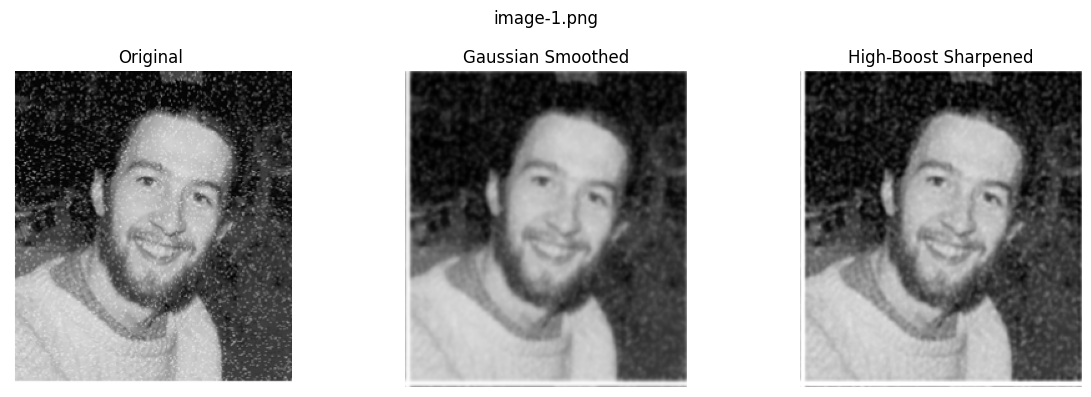

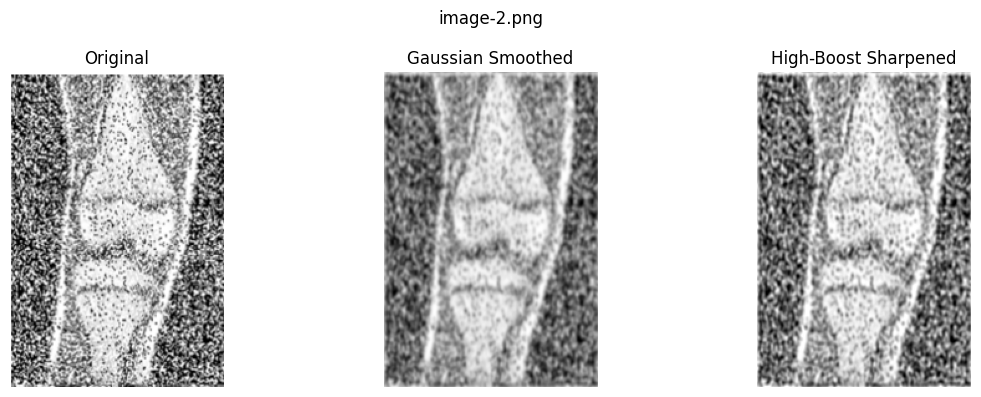

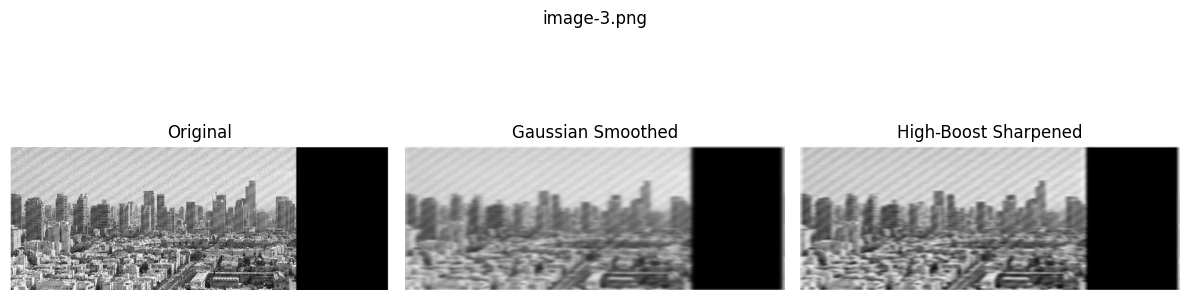

In [6]:
def high_boost_filter(img, cutoff=30, k=1.5):

    F, _, _, gaussian = frequency_filters(
        img, cutoff=cutoff
    )

    # High-boost frequency response
    high_boost_mask = 1 + k * (1 - gaussian)

    sharpened = apply_filter(
        F, high_boost_mask
    )

    return sharpened


sharpened_images = {}

for name, img in images.items():

    smooth = smoothed_images[name]["Gaussian"]

    sharp = high_boost_filter(
        smooth, cutoff=30, k=1.5
    )

    sharpened_images[name] = sharp

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(smooth, cmap="gray")
    plt.title("Gaussian Smoothed")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(sharp, cmap="gray")
    plt.title("High-Boost Sharpened")
    plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

Extract Binary Boundary Maps

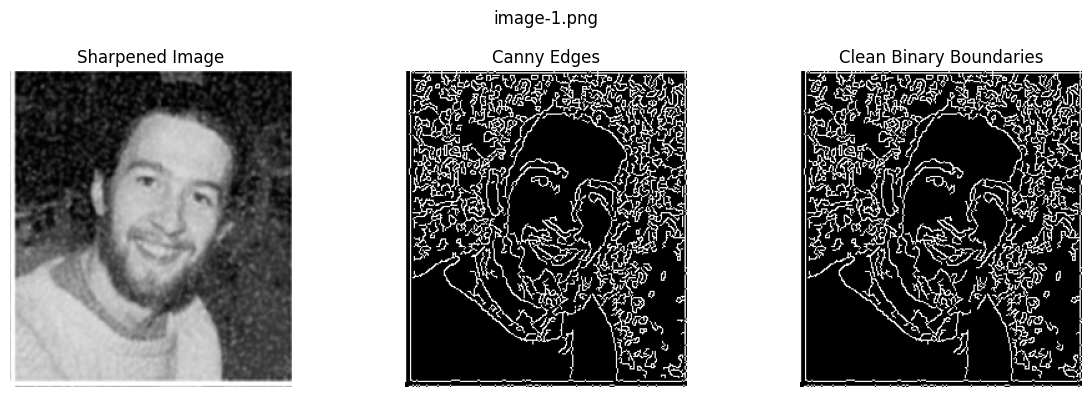

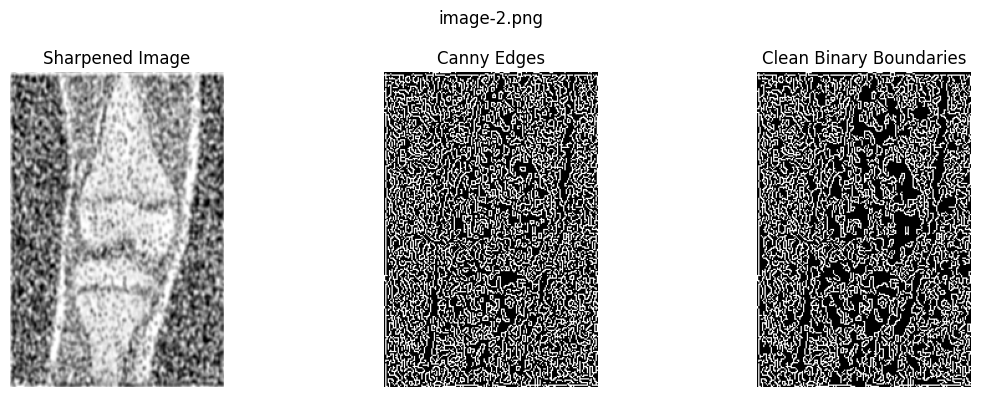

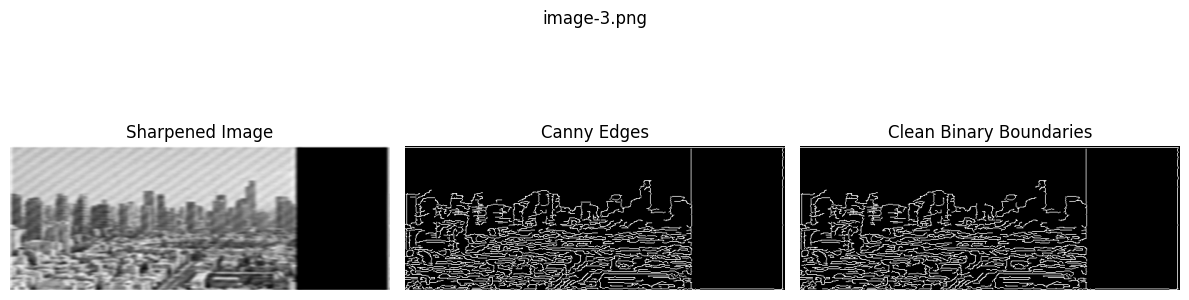

In [7]:
boundary_images = {}

for name, img in sharpened_images.items():

    # Canny Edge Detection
    edges = cv2.Canny(
        img, threshold1=50, threshold2=150
    )

    # Remove small isolated edge components
    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            edges, connectivity=8
        )
    )

    clean_edges = np.zeros_like(edges)

    min_size = 15

    for i in range(1, num_labels):

        area = stats[
            i, cv2.CC_STAT_AREA
        ]

        if area >= min_size:
            clean_edges[labels == i] = 255

    boundary_images[name] = clean_edges

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Sharpened Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(edges, cmap="gray")
    plt.title("Canny Edges")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(clean_edges, cmap="gray")
    plt.title("Clean Binary Boundaries")
    plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

Compare Quantitative Results

In [8]:
metrics = []

for name, original in images.items():

    variants = {
        **smoothed_images[name],
        "High-Boost": sharpened_images[name]
    }

    for method, processed in variants.items():

        mse = np.mean(
            (
                original.astype(float) -
                processed.astype(float)
            ) ** 2
        )

        psnr = peak_signal_noise_ratio(
            original, processed, data_range=255
        )

        ssim = structural_similarity(
            original, processed, data_range=255
        )

        edges = cv2.Canny(processed, 50, 150)

        edge_density = (
            np.count_nonzero(edges) /
            edges.size
        )

        metrics.append({
            "Image": name,
            "Filter": method,
            "MSE": mse,
            "PSNR": psnr,
            "SSIM": ssim,
            "Edge Density": edge_density
        })

df = pd.DataFrame(metrics)

display(df.round(4))

,Image,Filter,MSE,PSNR,SSIM,Edge Density
0,image-1.png,Ideal,430.5250,21.7908,0.5191,0.1040
1,image-1.png,Butterworth,356.1060,22.6150,0.6214,0.0648
2,image-1.png,Gaussian,304.6792,23.2924,0.6809,0.0809
3,image-1.png,High-Boost,192.8806,25.2779,0.7948,0.1961
4,image-2.png,Ideal,1664.5419,15.9179,0.4535,0.2672
5,image-2.png,Butterworth,1281.3016,17.0543,0.5651,0.2679
6,image-2.png,Gaussian,1020.0811,18.0445,0.6657,0.3207
7,image-2.png,High-Boost,572.8237,20.5506,0.8428,0.3569
8,image-3.png,Ideal,828.1917,18.9495,0.4706,0.0805
9,image-3.png,Butterworth,715.0988,19.5871,0.5779,0.0623


Compare Different Cutoff Frequencies

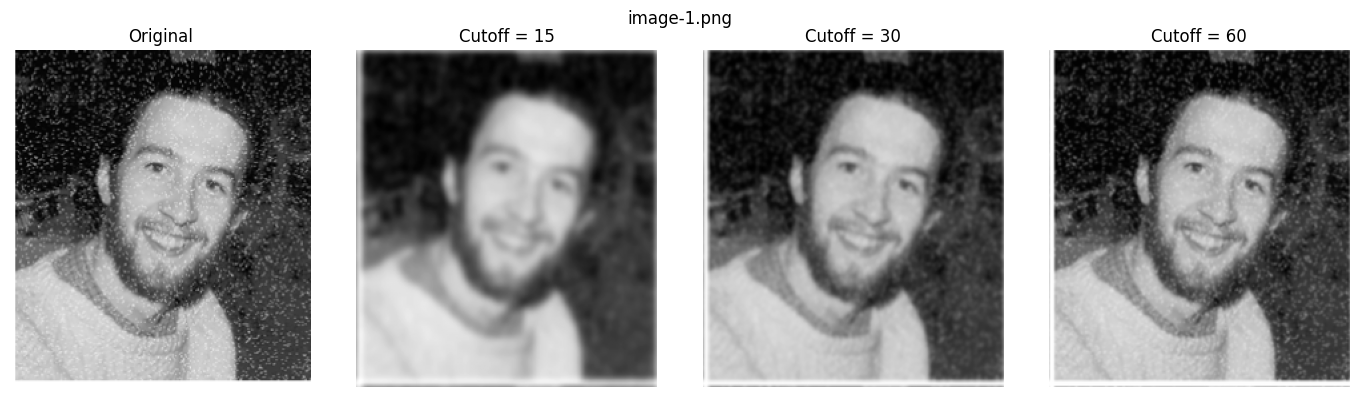

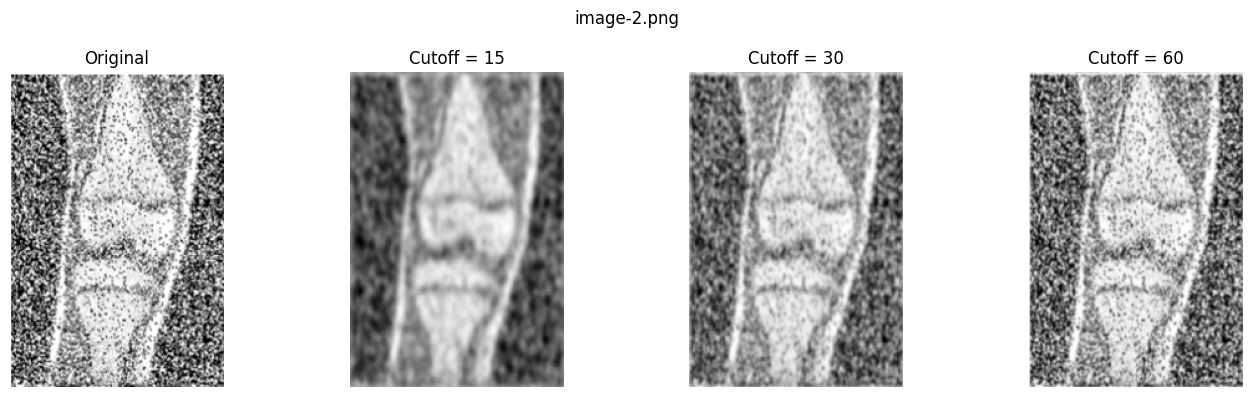

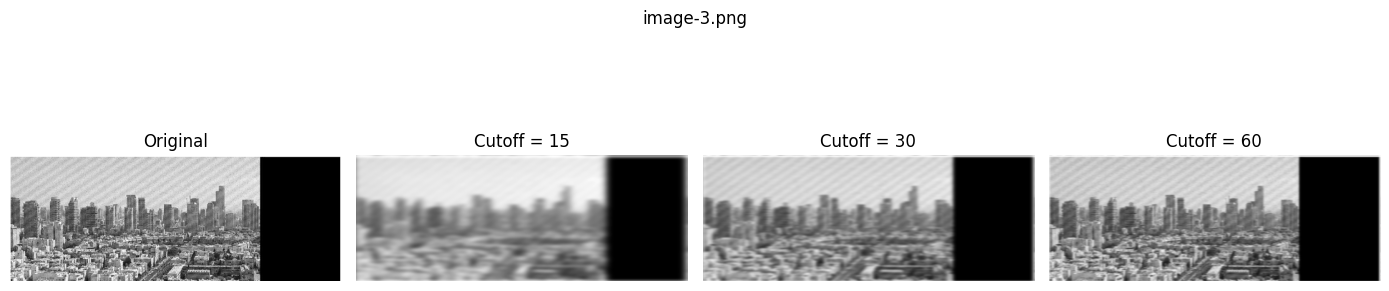

In [9]:
cutoffs = [15, 30, 60]

for name, img in images.items():

    plt.figure(figsize=(14, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original")
    plt.axis("off")

    for i, cutoff in enumerate(cutoffs):

        F, _, _, gaussian = frequency_filters(
            img, cutoff=cutoff
        )

        result = apply_filter(F, gaussian)

        plt.subplot(1, 4, i + 2)
        plt.imshow(result, cmap="gray")
        plt.title(f"Cutoff = {cutoff}")
        plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()